In [9]:
!pip install -q kagglehub imbalanced-learn

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

RANDOM_STATE = 42

In [11]:
import kagglehub
import os

path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")

print("Dataset path:", path)
print(os.listdir(path))

Using Colab cache for faster access to the 'creditcardfraud' dataset.
Dataset path: /kaggle/input/creditcardfraud
['creditcard.csv']


In [12]:
csv_path = os.path.join(path, "creditcard.csv")

df = pd.read_csv(csv_path)

df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [13]:
print(df.shape)
print()

print(df["Class"].value_counts())
print()

print(df["Class"].value_counts(normalize=True) * 100)

(284807, 31)

Class
0    284315
1       492
Name: count, dtype: int64

Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


In [14]:
class_counts = df["Class"].value_counts()

majority = class_counts[0]
minority = class_counts[1]

ratio = majority / minority

print(f"Legitimate transactions: {majority}")
print(f"Fraudulent transactions: {minority}")
print(f"Imbalance ratio: approximately 1:{ratio:.1f}")

Legitimate transactions: 284315
Fraudulent transactions: 492
Imbalance ratio: approximately 1:577.9


In [15]:
X = df.drop(columns="Class")
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTest class distribution:")
print(y_test.value_counts())

Training set: (227845, 30)
Test set: (56962, 30)

Training class distribution:
Class
0    227451
1       394
Name: count, dtype: int64

Test class distribution:
Class
0    56864
1       98
Name: count, dtype: int64


In [16]:
scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[["Time", "Amount"]] = scaler.fit_transform(
    X_train[["Time", "Amount"]]
)

X_test_scaled[["Time", "Amount"]] = scaler.transform(
    X_test[["Time", "Amount"]]
)

In [17]:
baseline_model = LogisticRegression(
    max_iter=1000,
    random_state=RANDOM_STATE
)

baseline_model.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000, random_state=42)

In [18]:
baseline_pred = baseline_model.predict(X_test_scaled)
baseline_proba = baseline_model.predict_proba(X_test_scaled)[:, 1]

In [19]:
baseline_accuracy = accuracy_score(y_test, baseline_pred)
baseline_precision = precision_score(y_test, baseline_pred)
baseline_recall = recall_score(y_test, baseline_pred)
baseline_f1 = f1_score(y_test, baseline_pred)
baseline_roc_auc = roc_auc_score(y_test, baseline_proba)
baseline_pr_auc = average_precision_score(y_test, baseline_proba)

print(f"Accuracy:  {baseline_accuracy:.4f}")
print(f"Precision: {baseline_precision:.4f}")
print(f"Recall:    {baseline_recall:.4f}")
print(f"F1-score:  {baseline_f1:.4f}")
print(f"ROC-AUC:   {baseline_roc_auc:.4f}")
print(f"PR-AUC:    {baseline_pr_auc:.4f}")

Accuracy:  0.9992
Precision: 0.8289
Recall:    0.6429
F1-score:  0.7241
ROC-AUC:   0.9559
PR-AUC:    0.7432


In [20]:
print(classification_report(y_test, baseline_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.83      0.64      0.72        98

    accuracy                           1.00     56962
   macro avg       0.91      0.82      0.86     56962
weighted avg       1.00      1.00      1.00     56962



In [21]:
print("Confusion matrix:")
print(confusion_matrix(y_test, baseline_pred))

Confusion matrix:
[[56851    13]
 [   35    63]]


In [22]:
weighted_model = LogisticRegression(
    max_iter=1000,
    random_state=RANDOM_STATE,
    class_weight="balanced"
)

weighted_model.fit(X_train_scaled, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

In [23]:
weighted_pred = weighted_model.predict(X_test_scaled)
weighted_proba = weighted_model.predict_proba(X_test_scaled)[:, 1]

In [24]:
weighted_accuracy = accuracy_score(y_test, weighted_pred)
weighted_precision = precision_score(y_test, weighted_pred)
weighted_recall = recall_score(y_test, weighted_pred)
weighted_f1 = f1_score(y_test, weighted_pred)
weighted_roc_auc = roc_auc_score(y_test, weighted_proba)
weighted_pr_auc = average_precision_score(y_test, weighted_proba)

print(f"Accuracy:  {weighted_accuracy:.4f}")
print(f"Precision: {weighted_precision:.4f}")
print(f"Recall:    {weighted_recall:.4f}")
print(f"F1-score:  {weighted_f1:.4f}")
print(f"ROC-AUC:   {weighted_roc_auc:.4f}")
print(f"PR-AUC:    {weighted_pr_auc:.4f}")

Accuracy:  0.9755
Precision: 0.0610
Recall:    0.9184
F1-score:  0.1144
ROC-AUC:   0.9722
PR-AUC:    0.7159


In [25]:
print(classification_report(y_test, weighted_pred))

              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56864
           1       0.06      0.92      0.11        98

    accuracy                           0.98     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.98      0.99     56962



In [26]:
print("Confusion matrix:")
print(confusion_matrix(y_test, weighted_pred))

Confusion matrix:
[[55478  1386]
 [    8    90]]


In [27]:
results = pd.DataFrame({
    "Method": [
        "Baseline",
        "Class Weight"
    ],
    "Accuracy": [
        baseline_accuracy,
        weighted_accuracy
    ],
    "Precision": [
        baseline_precision,
        weighted_precision
    ],
    "Recall": [
        baseline_recall,
        weighted_recall
    ],
    "F1": [
        baseline_f1,
        weighted_f1
    ],
    "ROC-AUC": [
        baseline_roc_auc,
        weighted_roc_auc
    ],
    "PR-AUC": [
        baseline_pr_auc,
        weighted_pr_auc
    ]
})

results.round(4)

,Method,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Baseline,0.9992,0.8289,0.6429,0.7241,0.9559,0.7432
1,Class Weight,0.9755,0.0610,0.9184,0.1144,0.9722,0.7159


In [28]:
undersampler = RandomUnderSampler(
    random_state=RANDOM_STATE
)

X_train_under, y_train_under = undersampler.fit_resample(
    X_train_scaled,
    y_train
)

print("Before undersampling:")
print(y_train.value_counts())

print("\nAfter undersampling:")
print(y_train_under.value_counts())

Before undersampling:
Class
0    227451
1       394
Name: count, dtype: int64

After undersampling:
Class
0    394
1    394
Name: count, dtype: int64


In [29]:
under_model = LogisticRegression(
    max_iter=1000,
    random_state=RANDOM_STATE
)

under_model.fit(X_train_under, y_train_under)

LogisticRegression(max_iter=1000, random_state=42)

In [30]:
under_pred = under_model.predict(X_test_scaled)
under_proba = under_model.predict_proba(X_test_scaled)[:, 1]

In [31]:
under_accuracy = accuracy_score(y_test, under_pred)
under_precision = precision_score(y_test, under_pred)
under_recall = recall_score(y_test, under_pred)
under_f1 = f1_score(y_test, under_pred)
under_roc_auc = roc_auc_score(y_test, under_proba)
under_pr_auc = average_precision_score(y_test, under_proba)

print(f"Accuracy:  {under_accuracy:.4f}")
print(f"Precision: {under_precision:.4f}")
print(f"Recall:    {under_recall:.4f}")
print(f"F1-score:  {under_f1:.4f}")
print(f"ROC-AUC:   {under_roc_auc:.4f}")
print(f"PR-AUC:    {under_pr_auc:.4f}")

Accuracy:  0.9603
Precision: 0.0384
Recall:    0.9184
F1-score:  0.0738
ROC-AUC:   0.9759
PR-AUC:    0.6778


In [32]:
print(classification_report(y_test, under_pred))

              precision    recall  f1-score   support

           0       1.00      0.96      0.98     56864
           1       0.04      0.92      0.07        98

    accuracy                           0.96     56962
   macro avg       0.52      0.94      0.53     56962
weighted avg       1.00      0.96      0.98     56962



In [33]:
print("Confusion matrix:")
print(confusion_matrix(y_test, under_pred))

Confusion matrix:
[[54612  2252]
 [    8    90]]


In [34]:
results = pd.DataFrame({
    "Method": [
        "Baseline",
        "Class Weight",
        "Undersampling"
    ],
    "Accuracy": [
        baseline_accuracy,
        weighted_accuracy,
        under_accuracy
    ],
    "Precision": [
        baseline_precision,
        weighted_precision,
        under_precision
    ],
    "Recall": [
        baseline_recall,
        weighted_recall,
        under_recall
    ],
    "F1": [
        baseline_f1,
        weighted_f1,
        under_f1
    ],
    "ROC-AUC": [
        baseline_roc_auc,
        weighted_roc_auc,
        under_roc_auc
    ],
    "PR-AUC": [
        baseline_pr_auc,
        weighted_pr_auc,
        under_pr_auc
    ]
})

results.round(4)

,Method,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Baseline,0.9992,0.8289,0.6429,0.7241,0.9559,0.7432
1,Class Weight,0.9755,0.0610,0.9184,0.1144,0.9722,0.7159
2,Undersampling,0.9603,0.0384,0.9184,0.0738,0.9759,0.6778


In [35]:
smote = SMOTE(
    random_state=RANDOM_STATE
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_scaled,
    y_train
)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_smote.value_counts())

Before SMOTE:
Class
0    227451
1       394
Name: count, dtype: int64

After SMOTE:
Class
0    227451
1    227451
Name: count, dtype: int64


In [36]:
smote_model = LogisticRegression(
    max_iter=1000,
    random_state=RANDOM_STATE
)

smote_model.fit(X_train_smote, y_train_smote)

LogisticRegression(max_iter=1000, random_state=42)

In [38]:
smote_pred = smote_model.predict(X_test_scaled)
smote_proba = smote_model.predict_proba(X_test_scaled) [:, 1]

In [39]:
smote_accuracy = accuracy_score(y_test, smote_pred)
smote_precision = precision_score(y_test, smote_pred)
smote_recall = recall_score(y_test, smote_pred)
smote_f1 = f1_score(y_test, smote_pred)
smote_roc_auc = roc_auc_score(y_test, smote_proba)
smote_pr_auc = average_precision_score(y_test, smote_proba)

print(f"Accuracy:  {smote_accuracy:.4f}")
print(f"Precision: {smote_precision:.4f}")
print(f"Recall:    {smote_recall:.4f}")
print(f"F1-score:  {smote_f1:.4f}")
print(f"ROC-AUC:   {smote_roc_auc:.4f}")
print(f"PR-AUC:    {smote_pr_auc:.4f}")


Accuracy:  0.9742
Precision: 0.0580
Recall:    0.9184
F1-score:  0.1092
ROC-AUC:   0.9699
PR-AUC:    0.7249


In [40]:
print(classification_report(y_test, smote_pred))

              precision    recall  f1-score   support

           0       1.00      0.97      0.99     56864
           1       0.06      0.92      0.11        98

    accuracy                           0.97     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.97      0.99     56962



In [41]:
print("Confusion matrix:")
print(confusion_matrix(y_test, smote_pred))

Confusion matrix:
[[55403  1461]
 [    8    90]]


In [42]:
results = pd.DataFrame({
    "Method": [
        "Baseline",
        "Class Weight",
        "Undersampling",
        "SMOTE"
    ],
    "Accuracy": [
        baseline_accuracy,
        weighted_accuracy,
        under_accuracy,
        smote_accuracy
    ],
    "Precision": [
        baseline_precision,
        weighted_precision,
        under_precision,
        smote_precision
    ],
    "Recall": [
        baseline_recall,
        weighted_recall,
        under_recall,
        smote_recall
    ],
    "F1": [
        baseline_f1,
        weighted_f1,
        under_f1,
        smote_f1
    ],
    "ROC-AUC": [
        baseline_roc_auc,
        weighted_roc_auc,
        under_roc_auc,
        smote_roc_auc
    ],
    "PR-AUC": [
        baseline_pr_auc,
        weighted_pr_auc,
        under_pr_auc,
        smote_pr_auc
    ]
})

results.round(4)

,Method,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Baseline,0.9992,0.8289,0.6429,0.7241,0.9559,0.7432
1,Class Weight,0.9755,0.0610,0.9184,0.1144,0.9722,0.7159
2,Undersampling,0.9603,0.0384,0.9184,0.0738,0.9759,0.6778
3,SMOTE,0.9742,0.0580,0.9184,0.1092,0.9699,0.7249


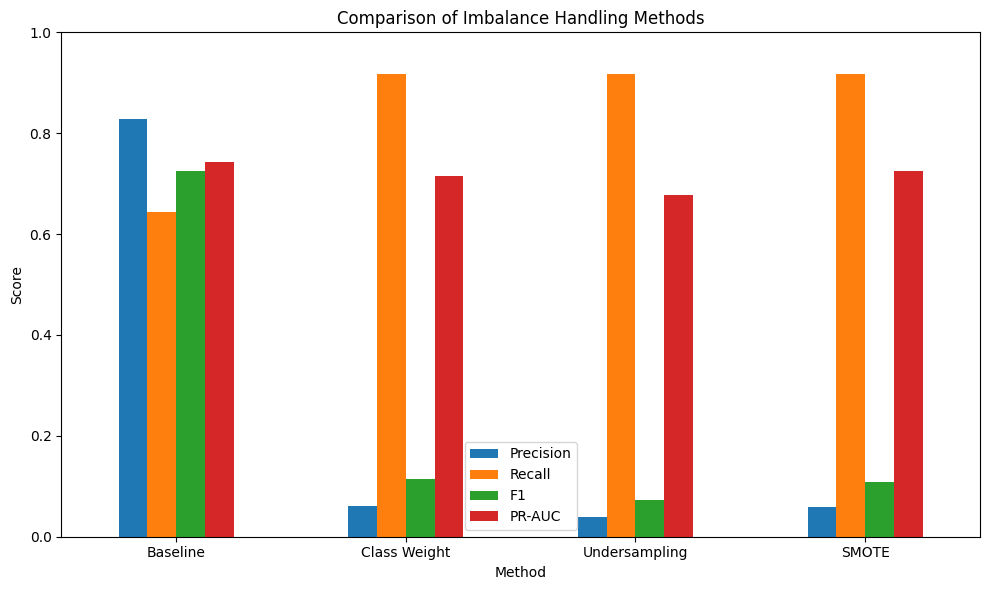

In [43]:
results_plot = results.set_index("Method")

results_plot[["Precision", "Recall", "F1", "PR-AUC"]].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Comparison of Imbalance Handling Methods")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="best")
plt.tight_layout()
plt.show()

In [45]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline as SkPipeline
from imblearn.pipeline import Pipeline as ImbPipeline

In [46]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

scoring = {
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision"
}

In [47]:
numeric_features = ["Time", "Amount"]

preprocessor = ColumnTransformer(
    transformers=[
        ("scale", StandardScaler(), numeric_features)
    ],
    remainder="passthrough"
)

In [48]:
baseline_cv_model = ImbPipeline([
    ("preprocess", preprocessor),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    ))
])

baseline_cv = cross_validate(
    baseline_cv_model,
    X,
    y,
    cv=cv,
    scoring=scoring
)

In [49]:
weighted_cv_model = ImbPipeline([
    ("preprocess", preprocessor),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE,
        class_weight="balanced"
    ))
])

weighted_cv = cross_validate(
    weighted_cv_model,
    X,
    y,
    cv=cv,
    scoring=scoring
)

In [50]:
under_cv_model = ImbPipeline([
    ("preprocess", preprocessor),
    ("undersample", RandomUnderSampler(
        random_state=RANDOM_STATE
    )),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    ))
])

under_cv = cross_validate(
    under_cv_model,
    X,
    y,
    cv=cv,
    scoring=scoring
)

In [51]:
smote_cv_model = ImbPipeline([
    ("preprocess", preprocessor),
    ("smote", SMOTE(
        random_state=RANDOM_STATE
    )),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    ))
])

smote_cv = cross_validate(
    smote_cv_model,
    X,
    y,
    cv=cv,
    scoring=scoring
)

In [52]:
def summarize_cv(name, cv_results):
    return {
        "Method": name,
        "Precision Mean": cv_results["test_precision"].mean(),
        "Precision Std": cv_results["test_precision"].std(),
        "Recall Mean": cv_results["test_recall"].mean(),
        "Recall Std": cv_results["test_recall"].std(),
        "F1 Mean": cv_results["test_f1"].mean(),
        "F1 Std": cv_results["test_f1"].std(),
        "ROC-AUC Mean": cv_results["test_roc_auc"].mean(),
        "PR-AUC Mean": cv_results["test_pr_auc"].mean()
    }


cv_results_table = pd.DataFrame([
    summarize_cv("Baseline", baseline_cv),
    summarize_cv("Class Weight", weighted_cv),
    summarize_cv("Undersampling", under_cv),
    summarize_cv("SMOTE", smote_cv)
])

cv_results_table.round(4)

,Method,Precision Mean,Precision Std,Recall Mean,Recall Std,F1 Mean,F1 Std,ROC-AUC Mean,PR-AUC Mean
0,Baseline,0.8738,0.0401,0.6220,0.0401,0.7256,0.0304,0.9738,0.7577
1,Class Weight,0.0651,0.0034,0.9126,0.0248,0.1214,0.0058,0.9795,0.7422
2,Undersampling,0.0488,0.0068,0.9146,0.0211,0.0926,0.0122,0.9769,0.7273
3,SMOTE,0.0592,0.0036,0.9105,0.0263,0.1111,0.0063,0.9778,0.7404


In [53]:
cv_results_table.round(4)

,Method,Precision Mean,Precision Std,Recall Mean,Recall Std,F1 Mean,F1 Std,ROC-AUC Mean,PR-AUC Mean
0,Baseline,0.8738,0.0401,0.6220,0.0401,0.7256,0.0304,0.9738,0.7577
1,Class Weight,0.0651,0.0034,0.9126,0.0248,0.1214,0.0058,0.9795,0.7422
2,Undersampling,0.0488,0.0068,0.9146,0.0211,0.0926,0.0122,0.9769,0.7273
3,SMOTE,0.0592,0.0036,0.9105,0.0263,0.1111,0.0063,0.9778,0.7404


In [54]:
cv_results_table.sort_values(
    by="PR-AUC Mean",
    ascending=False
).round(4)

,Method,Precision Mean,Precision Std,Recall Mean,Recall Std,F1 Mean,F1 Std,ROC-AUC Mean,PR-AUC Mean
0,Baseline,0.8738,0.0401,0.6220,0.0401,0.7256,0.0304,0.9738,0.7577
1,Class Weight,0.0651,0.0034,0.9126,0.0248,0.1214,0.0058,0.9795,0.7422
3,SMOTE,0.0592,0.0036,0.9105,0.0263,0.1111,0.0063,0.9778,0.7404
2,Undersampling,0.0488,0.0068,0.9146,0.0211,0.0926,0.0122,0.9769,0.7273


In [55]:
cv_results_table.sort_values(
    by="F1 Mean",
    ascending=False
).round(4)

,Method,Precision Mean,Precision Std,Recall Mean,Recall Std,F1 Mean,F1 Std,ROC-AUC Mean,PR-AUC Mean
0,Baseline,0.8738,0.0401,0.6220,0.0401,0.7256,0.0304,0.9738,0.7577
1,Class Weight,0.0651,0.0034,0.9126,0.0248,0.1214,0.0058,0.9795,0.7422
3,SMOTE,0.0592,0.0036,0.9105,0.0263,0.1111,0.0063,0.9778,0.7404
2,Undersampling,0.0488,0.0068,0.9146,0.0211,0.0926,0.0122,0.9769,0.7273


In [56]:
for name, cv_result in [
    ("Baseline", baseline_cv),
    ("Class Weight", weighted_cv),
    ("Undersampling", under_cv),
    ("SMOTE", smote_cv)
]:
    print(name)
    print("F1 scores:", np.round(cv_result["test_f1"], 4))
    print("Mean F1:", round(cv_result["test_f1"].mean(), 4))
    print("Std F1:", round(cv_result["test_f1"].std(), 4))
    print()

Baseline
F1 scores: [0.6951 0.7086 0.6994 0.7636 0.7614]
Mean F1: 0.7256
Std F1: 0.0304

Class Weight
F1 scores: [0.1324 0.1213 0.1155 0.1176 0.1204]
Mean F1: 0.1214
Std F1: 0.0058

Undersampling
F1 scores: [0.0881 0.097  0.1142 0.0801 0.0835]
Mean F1: 0.0926
Std F1: 0.0122

SMOTE
F1 scores: [0.1231 0.1119 0.1078 0.1067 0.1062]
Mean F1: 0.1111
Std F1: 0.0063



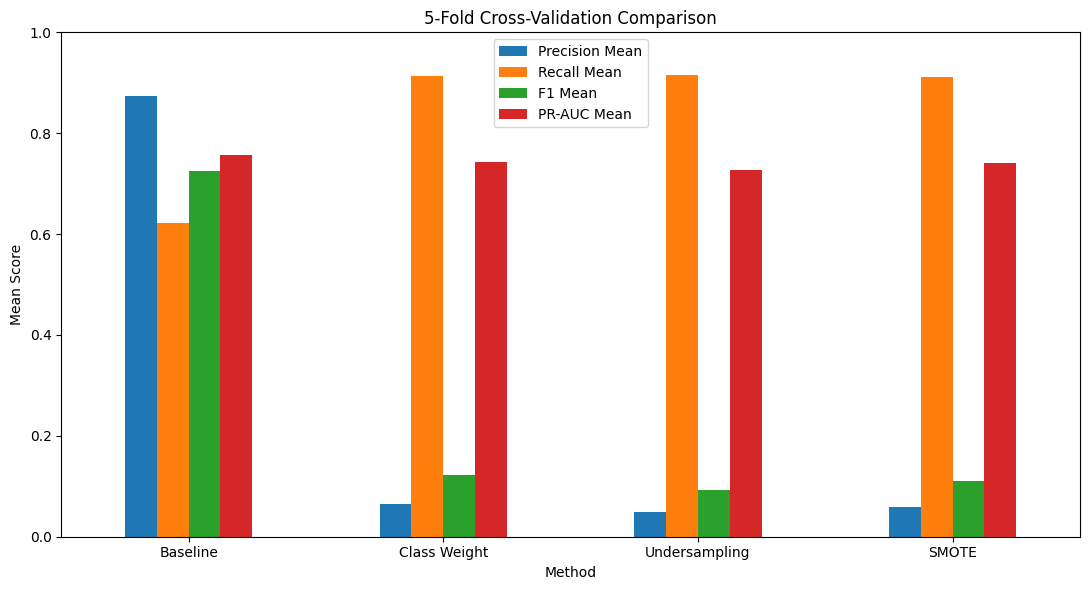

In [57]:
plot_data = cv_results_table.set_index("Method")

plot_data[
    ["Precision Mean", "Recall Mean", "F1 Mean", "PR-AUC Mean"]
].plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("5-Fold Cross-Validation Comparison")
plt.ylabel("Mean Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()